# Single Fidelity Surrogate Model Comparison

This workbook is aimed at testing the convergence of single fidelity models to data sets taken from analytical functions. The goal is to show how the functions increase in accuracy as the number of samples increase.

In [3]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt

import examples.multi_fidelity_functions as mfs
from SurrogateModels import mfsnn
from torch import nn as tnn

The following creates some scaffolding for systematically creating and assessing kriging models.

In [ ]:
import time
import csv


def create_test_points(func: mfs.MultiFidelityTemplate, n=2000):
    # Create a set of samples to create a ground truth
    X_test = func.sample_random(n)
    y_test = func.high_fidelity(X_test)
    return X_test, y_test


def generate_nn_model(
    name,
    func: mfs.MultiFidelityTemplate,
    n,
    seed,
    X_test,
    y_test,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    weight_decay=1e-6,
    activation=tnn.Tanh(),
    epochs=1000,
    x_transform=True,
    bounds=None,
):
    X_train = func.sample_random(n, seed=seed)
    # X_train = func.sample_uniform(n)
    y_train = func.high_fidelity(X_train)
    training_data = zip(X_train, y_train)
    with open("training_data.txt", "w") as file:
        for row in training_data:
            file.write(f"{row[0].tolist()},{row[1].tolist()}\n")
    # Setup timer to gauge model training time
    t0 = time.perf_counter()
    model = mfsnn.MLPNetwork(
        X=X_train,
        y=y_train,
        X_test=X_test,
        y_test=y_test,
        activation=tnn.Tanh(),
        hidden_layer_size=hidden_layer_size,
        epochs=epochs,
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        scale_input=x_transform,
        bounds = bounds
    )
    model_training_time = time.perf_counter() - t0

    t0 = time.perf_counter()
    error = model.model_error(X_test, y_test)
    evaluation_time = time.perf_counter() - t0
    model_error = model.model_error(X_test, y_test)
    print(
        f"Run {name} :: seed {seed} :: points {n} :: error {error} :: train_time {model_training_time} :: evaluation_time {evaluation_time}"
    )
    return model, error, model_training_time, evaluation_time


def generate_model_comparisons(
    name,
    func: mfs.MultiFidelityTemplate,
    X_test,
    y_test,
    sample_low=5,
    sample_high=105,
    step_size=5,
    seeds=5,
    points=[],
    model_error=[],
    training_time=[],
    evaluation_time=[],
    hidden_layer_size=[20, 20, 20],
    learning_rate=1e-4,
    output_file="model_comparison_output.csv",
):
    # Generate a Kriging model of the data and test accuracy using a number of random sample points
    n_points = list(range(sample_low, sample_high, step_size))
    for seed in range(0, seeds):
        for n in n_points:
            X_train = func.sample_random(n, seed=seed)
            # X_train = func.sample_uniform(n)
            y_train = func.high_fidelity(X_train)
            # Setup timer to gauge model training time
            t0 = time.perf_counter()

            model = mfsnn.MLPNetwork(
                X=X_train,
                y=y_train,
                X_test=X_test,
                y_test=y_test,
                activation=tnn.Tanh(),
                hidden_layer_size=hidden_layer_size,
                epochs=1000,
                learning_rate=learning_rate,
                weight_decay=1e-6,
                bounds = func.bounds,
                scale_input=True,
            )

            training_time.append(time.perf_counter() - t0)

            t0 = time.perf_counter()
            error = model.model_error(X_test, y_test)
            evaluation_time.append(time.perf_counter() - t0)
            model_error.append(model.model_error(X_test, y_test))
            points.append(n)
            print(
                f"Run {name} :: seed {seed} :: points {n} :: error {error} :: train_time {training_time[-1]} "
            )
            with open(output_file, "w", newline="") as file:
                writer = csv.writer(file)
                writer.writerow(
                    [
                        points[-1],
                        model_error[-1],
                        training_time[-1],
                        evaluation_time[-1],
                    ]
                )
    return points, model_error, evaluation_time, training_time


def plot_error_measure(
    points, error, name, color="blue", marker="o", label="Test", ax=None
):
    if ax == None:
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    ax.scatter(
        points,
        error,
        color=color,
        label=label,
        marker=marker,
    )
    ax.set_xlabel("Samples")
    ax.set_ylabel("RMS Error")
    ax.legend()
    ax.grid()
    ax.set_yscale("log")
    return ax


def export_to_csv(output_file, points, model_error, training_time, evaluation_time):
    with open(output_file, "w", newline="") as file:
        writer = csv.writer(file)
        for i, val in enumerate(points):
            writer.writerow(
                [
                    val,
                    model_error[i],
                    training_time[i],
                    evaluation_time[i],
                ]
            )

In [ ]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

model, error, model_training_time, evaluation_time = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[30, 30, 15],
    learning_rate=1e-2,
    weight_decay=1e-3,
    activation=tnn.Tanh(),
    epochs=1000,
    x_transform=True,
    bounds=my_function.bounds,
)

Run 2D :: seed 1 :: points 1000 :: error 0.008298287202671742 :: train_time 384.4823334000539 :: evaluation_time 0.027209199965000153


[tensor(0.0029), tensor(0.0025), tensor(0.0020), tensor(0.0017), tensor(0.0013), tensor(0.0011), tensor(0.0009), tensor(0.0007), tensor(0.0004), tensor(0.0003), tensor(0.0002), tensor(0.0001), tensor(0.0001), tensor(7.8730e-05), tensor(6.4236e-05), tensor(5.4184e-05), tensor(4.6550e-05), tensor(3.9838e-05), tensor(3.3831e-05), tensor(2.8383e-05), tensor(2.3577e-05), tensor(1.9729e-05), tensor(1.6718e-05), tensor(1.4215e-05), tensor(1.2134e-05), tensor(1.0458e-05), tensor(9.1209e-06), tensor(8.0555e-06), tensor(7.1046e-06), tensor(6.1000e-06), tensor(5.0479e-06), tensor(4.2453e-06), tensor(3.6944e-06), tensor(3.2916e-06), tensor(2.9591e-06), tensor(2.6520e-06), tensor(2.3791e-06), tensor(2.1490e-06), tensor(1.9539e-06), tensor(1.7763e-06), tensor(1.5995e-06), tensor(1.4347e-06), tensor(1.2947e-06), tensor(1.1801e-06), tensor(1.0845e-06), tensor(1.0134e-06), tensor(9.5558e-07), tensor(9.0813e-07), tensor(8.6695e-07), tensor(8.3079e-07), tensor(7.8589e-07), tensor(7.3383e-07), tensor(6.83

<Axes3D: title={'center': 'Data'}, xlabel='x1', ylabel='x2', zlabel='f(x)'>

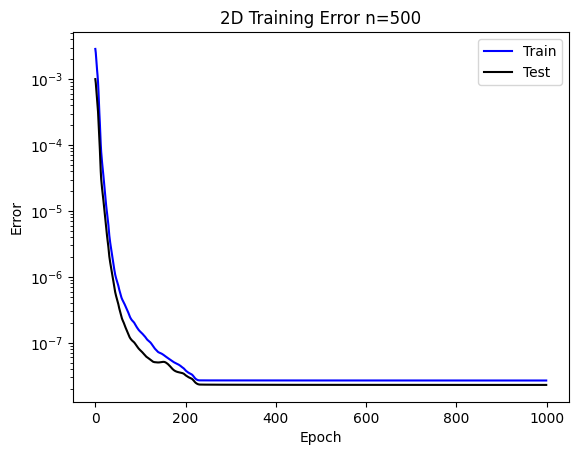

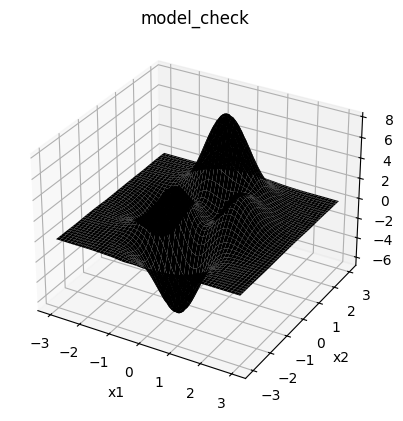

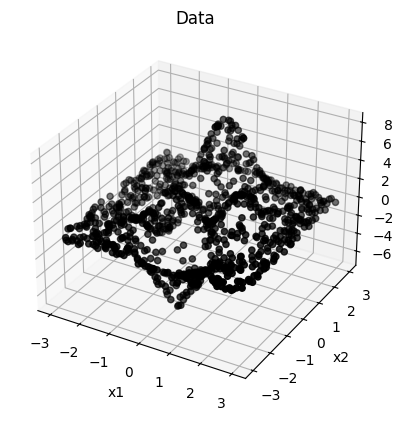

In [10]:
model.plot_training_error("2D Training Error n=500")
print(model.training_error)
model.plot_model(my_function.bounds,"model_check")
model.plot_data()

In [32]:
key = "2D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=50,
    sample_high=1000,
    step_size=100,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-3
)

Run 2D :: seed 0 :: points 50 :: error 1.5555843246259773 :: train_time 73.05351639998844 
Run 2D :: seed 0 :: points 150 :: error 1.7718163178996855 :: train_time 48.15164279998862 
Run 2D :: seed 0 :: points 250 :: error 1.6503532007967028 :: train_time 66.07729400001699 
Run 2D :: seed 0 :: points 350 :: error 0.07890815180689643 :: train_time 113.89762499998324 
Run 2D :: seed 0 :: points 450 :: error 1.4344059676400784 :: train_time 1233.3096556999953 
Run 2D :: seed 0 :: points 550 :: error 0.060218788183965005 :: train_time 132.51535860000877 
Run 2D :: seed 0 :: points 650 :: error 0.07164553291168385 :: train_time 135.9411479999835 
Run 2D :: seed 0 :: points 750 :: error 0.07702547774460254 :: train_time 167.44832890000544 
Run 2D :: seed 0 :: points 850 :: error 1.7262569523013072 :: train_time 114.10428030000185 
Run 2D :: seed 0 :: points 950 :: error 0.06532035357225491 :: train_time 167.14950040000258 
Run 2D :: seed 1 :: points 50 :: error 1.433926083843048 :: train_tim

### 4-Dimensional Dataset

In [ ]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=5000)

model, error, model_training_time, evaluation_time = generate_nn_model(
    name=key,
    func=my_function,
    n=1000,
    seed=1,
    X_test=X_test,
    y_test=y_test,
    hidden_layer_size=[20, 20, 20],
    learning_rate=1,
    weight_decay=1e-6,
    activation=tnn.Tanh(),
    epochs=1000,
    x_transform=True,
    bounds=my_function.bounds,
)

KeyboardInterrupt: 

In [1]:
model.plot_training_error("4D Training Error n=500")
print(model.training_error)
model.plot_model(my_function.bounds,"model_check")
model.plot_data()

NameError: name 'model' is not defined

In [2]:
key = "4D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=500,
    sample_high=2001,
    step_size=500,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-2
)

NameError: name 'mfs' is not defined

In [ ]:
key = "6D"
my_function = mfs.increasing_dimensions[key]()
X_test, y_test = create_test_points(my_function, n=3000)

points=[]
model_error=[]
training_time=[]
evaluation_time=[]
iterations = []
points, model_error, evaluation_time, training_time = generate_model_comparisons(
    key,
    my_function,
    X_test=X_test,
    y_test=y_test,
    sample_low=500,
    sample_high=10000,
    step_size=500,
    seeds=3,    
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
    hidden_layer_size=[20,20,20],
    learning_rate=1e-3
)

In [26]:
report_name = "SingleFidelity4D_Cokriging_260531.csv"
print(model_error)
export_to_csv(
    report_name,
    points=points,
    model_error=model_error,
    training_time=training_time,
    evaluation_time=evaluation_time,
)

[0.02104515627990947]
